In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("Matplotlib imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Pandas version: 3.1.0
Matplotlib imported successfully!


In [ ]:
import pandas as pd

events = pd.read_csv("../data/events_clean.csv")
registrations = pd.read_csv("../data/registrations_clean.csv")
payments = pd.read_csv("../data/payments_clean.csv")

print("Events:", events.shape)
print("Registrations:", registrations.shape)
print("Payments:", payments.shape)

Events: (16, 10)
Registrations: (25, 4)
Payments: (25, 6)


In [ ]:
display(events.head())
display(registrations.head())
display(payments.head())

,event_id,title,category,start_date,end_date,price,capacity,registered_count,location,created_at
0,69bae9fc00dfe696c9e774d6,Pace,ongoing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6a9c8652099c39d36346e314,jg,Workshop,2026-09-20 00:00:00,NaN,10.0,NaN,NaN,Pune,2026-09-05 21:14:58
2,6a9c8696099c39d36346e31b,sdf,Technical,2026-09-19 00:00:00,2026-09-26 00:00:00,12.0,NaN,NaN,Pune,2026-09-05 21:16:06
3,6a9dc45981d44549fe1c957f,Techfest,Technical,2026-09-10 00:00:00,2026-09-12 00:00:00,0.0,NaN,NaN,Pune,2026-09-06 19:51:53
4,6a9dc8ec34e2bb61072b6044,cult akriti,Cultural,2026-09-06 00:00:00,2026-09-10 00:00:00,0.0,NaN,NaN,Pune,2026-09-06 20:11:24


,registration_id,user_id,event_id,created_at
0,69c2a098d9c6957086fc6cb1,69c178efa8a9cb6e01b9eb8c,69bae9fc00dfe696c9e774d6,2026-03-24 14:32:56
1,69c2ec5f027a4726e3e60577,69c2ec3f027a4726e3e6056b,69baad8b68510d673608c5e2,2026-03-24 19:56:15
2,69c2ec61027a4726e3e6057a,69c2ec3f027a4726e3e6056b,69bae9fc00dfe696c9e774d6,2026-03-24 19:56:17
3,69c2ec83027a4726e3e60594,69c2ec3f027a4726e3e6056b,69c2e1c3027a4726e3e6049b,2026-03-24 19:56:51
4,69c2ec85027a4726e3e60597,69c2ec3f027a4726e3e6056b,69baee9bf7ab5404e911cb41,2026-03-24 19:56:53


,payment_id,user_id,event_id,amount,currency,created_at
0,69d403474a90acab8e2c97c9,69bd9b3e101b1960c06231b5,69d402693ba01a89d85924b6,10,INR,2026-04-06 19:02:31
1,69d404084a90acab8e2c97da,69bd9b3e101b1960c06231b5,69d402693ba01a89d85924b6,10,INR,2026-04-06 19:05:44
2,69d404754a90acab8e2c97dd,69bd9b3e101b1960c06231b5,69d402693ba01a89d85924b6,10,INR,2026-04-06 19:07:33
3,6a9dccb592087f22e7776bdc,69bd9b3e101b1960c06231b5,6a9c8696099c39d36346e31b,12,INR,2026-09-06 20:27:33
4,6aa014f1f3b04790b7e67746,69bd9b3e101b1960c06231b5,6a9c8652099c39d36346e314,10,INR,2026-09-08 14:00:17


In [ ]:
print("EVENTS")
events.info()

print("\nREGISTRATIONS")
registrations.info()

print("\nPAYMENTS")
payments.info()

EVENTS
<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   event_id          16 non-null     str    
 1   title             16 non-null     str    
 2   category          16 non-null     str    
 3   start_date        15 non-null     str    
 4   end_date          14 non-null     str    
 5   price             15 non-null     float64
 6   capacity          4 non-null      float64
 7   registered_count  4 non-null      float64
 8   location          15 non-null     str    
 9   created_at        15 non-null     str    
dtypes: float64(3), str(7)
memory usage: 1.4 KB

REGISTRATIONS
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   registration_id  25 non-null     str  
 1   user_id          25 non-null     str  
 2   ev

In [ ]:
# Convert date columns into datetime format

date_columns = {
    "events": ["start_date", "end_date", "created_at"],
    "registrations": ["created_at"],
    "payments": ["created_at"]
}

for col in date_columns["events"]:
    events[col] = pd.to_datetime(events[col], errors="coerce")

for col in date_columns["registrations"]:
    registrations[col] = pd.to_datetime(registrations[col], errors="coerce")

for col in date_columns["payments"]:
    payments[col] = pd.to_datetime(payments[col], errors="coerce")

# Check results
print(events.dtypes)
print(registrations.dtypes)
print(payments.dtypes)

event_id                       str
title                          str
category                       str
start_date          datetime64[us]
end_date            datetime64[us]
price                      float64
capacity                   float64
registered_count           float64
location                       str
created_at          datetime64[us]
dtype: object
registration_id               str
user_id                       str
event_id                      str
created_at         datetime64[us]
dtype: object
payment_id               str
user_id                  str
event_id                 str
amount                 int64
currency                 str
created_at    datetime64[us]
dtype: object


In [ ]:
# Count registrations for each event
event_registrations = (
    registrations
    .groupby("event_id")
    .size()
    .reset_index(name="total_registrations")
)

# Join registration counts with event details
event_analysis = events.merge(
    event_registrations,
    on="event_id",
    how="left"
)

# Events without registrations should have count 0
event_analysis["total_registrations"] = (
    event_analysis["total_registrations"]
    .fillna(0)
    .astype(int)
)

# Sort by popularity
event_analysis = event_analysis.sort_values(
    "total_registrations",
    ascending=False
)

display(
    event_analysis[
        ["title", "category", "total_registrations"]
    ]
)

,title,category,total_registrations
0,Pace,ongoing,7
14,coding event,Technical,2
4,cult akriti,Cultural,1
1,jg,Workshop,1
15,codebite,Technical,1
5,marshai,Workshop,0
3,Techfest,Technical,0
2,sdf,Technical,0
7,fgs,Sports,0
6,dcas,Cultural,0


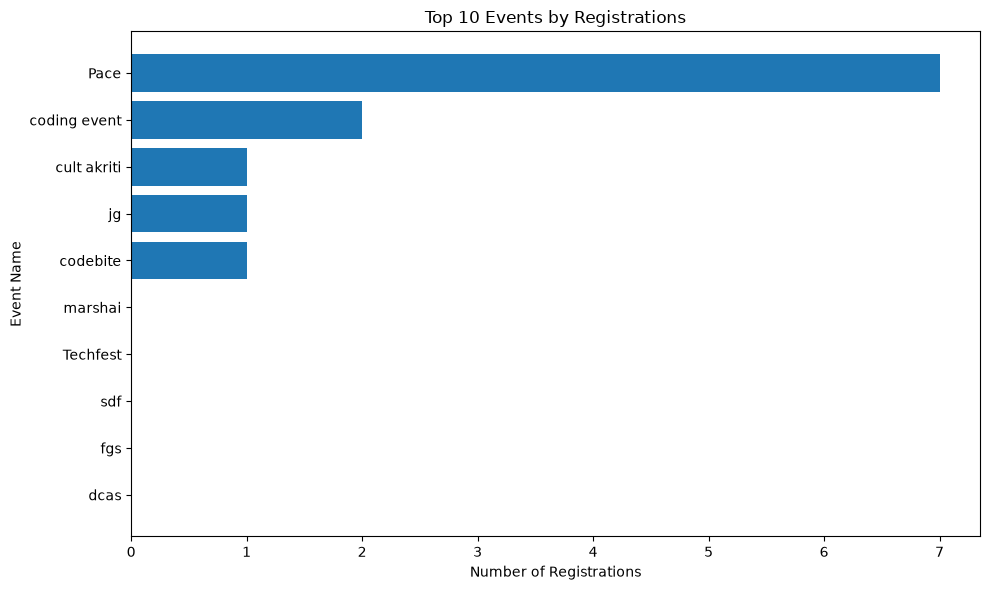

In [ ]:
plt.figure(figsize=(10, 6))

top_events = event_analysis.head(10)

plt.barh(
    top_events["title"],
    top_events["total_registrations"]
)

plt.xlabel("Number of Registrations")
plt.ylabel("Event Name")
plt.title("Top 10 Events by Registrations")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "../visualizations/event_popularity.png",
    dpi=300
)

plt.show()

In [ ]:
category_analysis = (
    event_analysis
    .groupby("category")["total_registrations"]
    .sum()
    .sort_values(ascending=False)
)

display(category_analysis)

category
ongoing      7
Technical    3
Cultural     1
Workshop     1
Sports       0
Name: total_registrations, dtype: int64

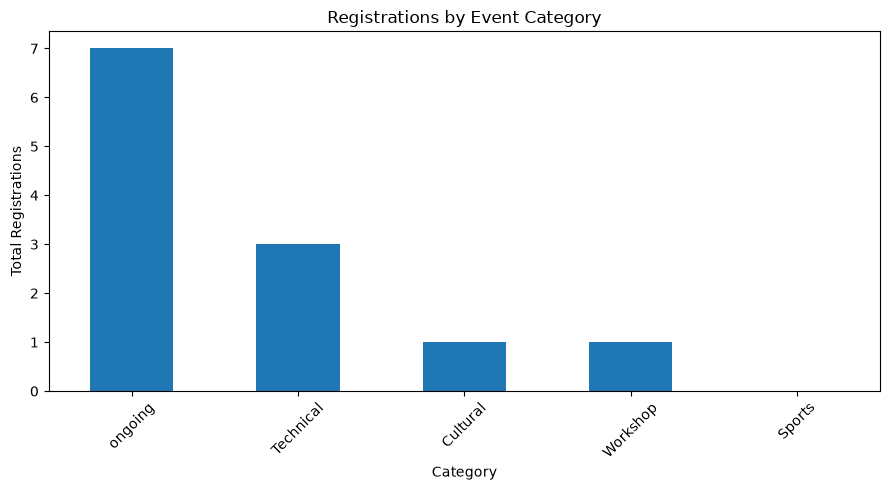

In [ ]:
plt.figure(figsize=(9, 5))

category_analysis.plot(kind="bar")

plt.title("Registrations by Event Category")
plt.xlabel("Category")
plt.ylabel("Total Registrations")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../visualizations/category_performance.png", dpi=300)
plt.show()

In [ ]:
monthly_registrations = (
    registrations
    .dropna(subset=["created_at"])
    .set_index("created_at")
    .resample("ME")
    .size()
)

display(monthly_registrations)

created_at
2026-03-31    14
2026-04-30     2
2026-05-31     0
2026-06-30     0
2026-07-31     2
2026-08-31     0
2026-09-30     4
2026-10-31     3
Freq: ME, dtype: int64

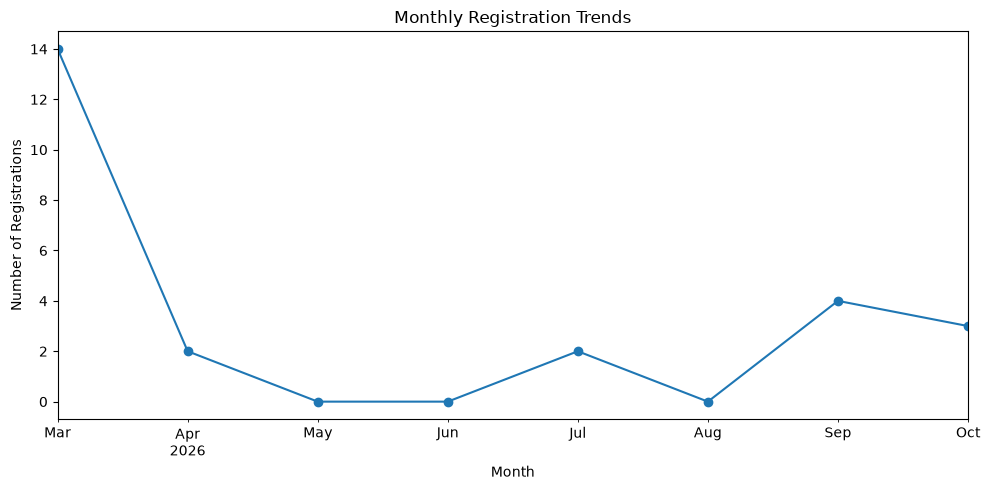

In [ ]:
plt.figure(figsize=(10, 5))

monthly_registrations.plot(marker="o")

plt.title("Monthly Registration Trends")
plt.xlabel("Month")
plt.ylabel("Number of Registrations")

plt.tight_layout()
plt.savefig("../visualizations/monthly_registrations.png", dpi=300)
plt.show()

In [ ]:
payment_analysis = (
    payments
    .groupby("event_id")
    .agg(
        payment_attempts=("payment_id", "count"),
        recorded_amount=("amount", "sum")
    )
    .reset_index()
    .merge(
        events[["event_id", "title"]],
        on="event_id",
        how="left"
    )
)

display(payment_analysis.sort_values(
    "recorded_amount",
    ascending=False
))

,event_id,payment_attempts,recorded_amount,title
6,6ad22fe55f1dec217c2d1ee0,3,300,coding event
7,test456,1,100,NaN
4,6ac17b5beca2a1000bc37601,6,72,dance
5,6ad22e1b5f1dec217c2d1ebe,4,48,codexthon
3,6abd565823f7408bd54ce6fd,3,45,twrtwer
1,6a9c8652099c39d36346e314,4,40,jg
0,69d402693ba01a89d85924b6,3,30,NaN
2,6a9c8696099c39d36346e31b,1,12,sdf


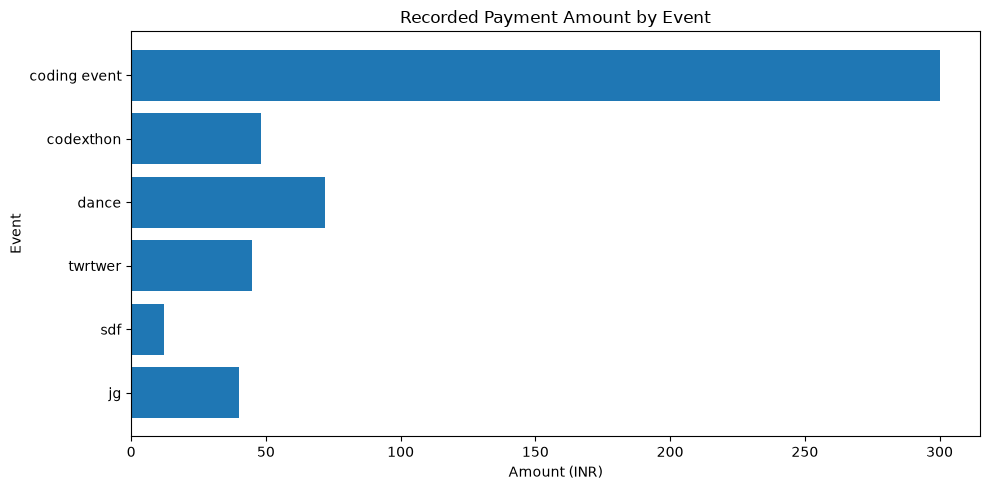

In [ ]:
payment_chart = payment_analysis.dropna(subset=["title"])

plt.figure(figsize=(10, 5))

plt.barh(
    payment_chart["title"],
    payment_chart["recorded_amount"]
)

plt.title("Recorded Payment Amount by Event")
plt.xlabel("Amount (INR)")
plt.ylabel("Event")

plt.tight_layout()
plt.savefig("../visualizations/payment_analysis.png", dpi=300)
plt.show()

In [ ]:
# 1. Total events
total_events = len(events)

# 2. Total registrations
total_registrations = len(registrations)

# 3. Registrations linked to exported events
matched_registrations = registrations[
    registrations["event_id"].isin(events["event_id"])
]

# 4. Unique attendees
unique_attendees = registrations["user_id"].nunique()

# 5. Repeat attendees
repeat_attendees = (
    registrations.groupby("user_id")["event_id"]
    .nunique()
    .gt(1)
    .sum()
)

# 6. Recorded payment amount
recorded_payment_amount = payments["amount"].sum()

print("FIestura Business Analytics - KPI Summary")
print("------------------------------------------")
print("Total Events:", total_events)
print("Total Registrations:", total_registrations)
print("Matched Registrations:", len(matched_registrations))
print("Unique Attendees:", unique_attendees)
print("Repeat Attendees:", repeat_attendees)
print("Recorded Payment Amount: ₹", recorded_payment_amount)

FIestura Business Analytics - KPI Summary
------------------------------------------
Total Events: 16
Total Registrations: 25
Matched Registrations: 12
Unique Attendees: 9
Repeat Attendees: 7
Recorded Payment Amount: ₹ 647


In [ ]:
print("TOP 5 EVENTS")
display(event_analysis.head(5)[
    ["title", "category", "total_registrations"]
])

print("CATEGORY PERFORMANCE")
display(category_analysis)

print("MONTHLY REGISTRATION TREND")
display(monthly_registrations)

print("PAYMENT ANALYSIS")
display(payment_analysis.sort_values(
    "recorded_amount", ascending=False
))

TOP 5 EVENTS


,title,category,total_registrations
0,Pace,ongoing,7
14,coding event,Technical,2
4,cult akriti,Cultural,1
1,jg,Workshop,1
15,codebite,Technical,1


CATEGORY PERFORMANCE


category
ongoing      7
Technical    3
Cultural     1
Workshop     1
Sports       0
Name: total_registrations, dtype: int64

MONTHLY REGISTRATION TREND


created_at
2026-03-31    14
2026-04-30     2
2026-05-31     0
2026-06-30     0
2026-07-31     2
2026-08-31     0
2026-09-30     4
2026-10-31     3
Freq: ME, dtype: int64

PAYMENT ANALYSIS


,event_id,payment_attempts,recorded_amount,title
6,6ad22fe55f1dec217c2d1ee0,3,300,coding event
7,test456,1,100,NaN
4,6ac17b5beca2a1000bc37601,6,72,dance
5,6ad22e1b5f1dec217c2d1ebe,4,48,codexthon
3,6abd565823f7408bd54ce6fd,3,45,twrtwer
1,6a9c8652099c39d36346e314,4,40,jg
0,69d402693ba01a89d85924b6,3,30,NaN
2,6a9c8696099c39d36346e31b,1,12,sdf


In [ ]:
# Keep registrations linked to exported events
matched = registrations[
    registrations["event_id"].isin(events["event_id"])
].copy()

# Count distinct events per user
matched_user_counts = (
    matched.groupby("user_id")["event_id"]
    .nunique()
)

# Calculate KPIs
matched_unique_attendees = matched["user_id"].nunique()

matched_repeat_attendees = (
    matched_user_counts > 1
).sum()

print("Matched unique attendees:", matched_unique_attendees)
print("Matched repeat attendees:", matched_repeat_attendees)

Matched unique attendees: 8
Matched repeat attendees: 3
